# E124: can the frozen reuse definition read a natural pronoun task on the small model?

**The answer.** No. We tried a task from ordinary text: choosing "he" or "she" to match a first name a few words
earlier. A readout trained on Pile text recovers the name's gender at the pronoun only weakly before the model's last
block, 0.73 at best against a bar of 0.90. By the definition's own rules the task is "unreadable", so nothing was
fine-tuned and the re-gating share was never read. This is a fact about the small model, not a new rule.


## What we were trying to test

The frozen reuse definition, after Jain et al. 2024, says a fine-tune reuses a capability C only if the original
model already possesses C. Possession means a straight-line readout, trained on Pile text, recovers C at some block
before the last, at accuracy 0.90 or more and at least 0.30 above a control readout. Only then does it go on to ask
whether the fine-tune carries to held-out inputs and breaks when C's direction is removed. The earlier small-model
tasks had no such C, or read "not through C". This experiment looked for natural tasks the model already half does,
so that the definition and the decomposition's re-gating share could be read on the same fine-tunes.

Two tasks were planned. **Agreement**, "is" or "are" after "the N of the N2", was dropped before any run: the first
32,768 Pile rows held 155 windows of the pattern, too few to train on. **Pronoun** ran. Its windows are Pile text
whose next word is " he" or " she", with exactly one first name 3 to 15 tokens back. C is the name's gender, from US
Social Security name counts. The pool is the 200 commonest single-token names per gender, after removing names that
are more often ordinary words, such as "Will" or "May".

Stage 0 ran alone on the unchanged model. The readout is a ridge probe trained on Pile positions after a training
name and scored on 800 windows of held-out names, at the position where the pronoun is chosen. Its control is the
same probe trained on a random bit fixed per name, after Hewitt and Liang: it shows what a probe fits from name
identity alone. A probe at 0.5 knows nothing; at 1.0 it reads gender perfectly.


## What we expected, and why

We expected the probe to pass at block 1 or 2, with a lean of 0.6, and the control near 0.5. The unchanged model
already picks the right pronoun nine times in ten, so gender must reach the prediction position somehow. The open
question was whether it arrives in a form one direction reads at 0.90. On the earlier case-label task the same probe
code read 0.99 at block 1, so the apparatus can pass when the property is held early.


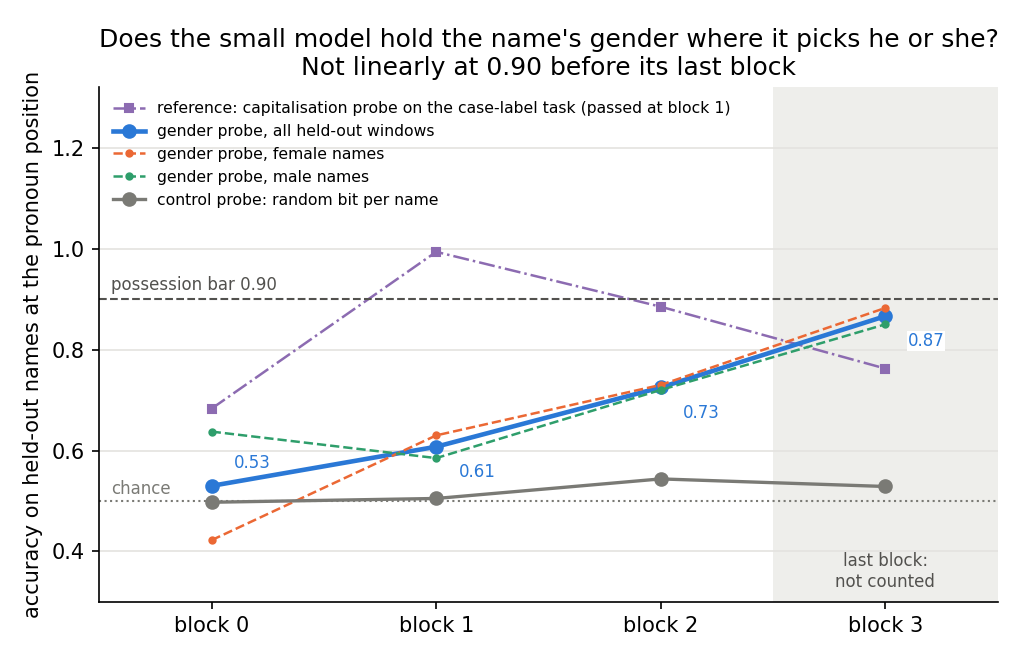

In [1]:
from IPython.display import Image

Image("../experiments/natural_tasks/figures/p0_blocks.png", width=680)


## Does the unchanged model hold the name's gender, readably, where it picks the pronoun?

**Reading it.** No. The gender probe, in blue, climbs from 0.53 at block 0 to 0.73 at block 2, the last block the
definition counts, against the dashed bar at 0.90. The grey control stays between 0.50 and 0.54 at every block, so
what the probe learns is gender, not name identity. Only the last block, shaded, comes near the bar at 0.87; the rule
does not count it, and it misses anyway. Female and male names track each other from block 1 on, so the miss is not
one gender dragging the mean down. The purple line is the case-label task's probe, which cleared the bar at block 1.


In [2]:
import json

s0 = json.load(open("../experiments/natural_tasks/results/stage0.json"))
acc = s0["w0_accuracy"]["natural"]
print("Unchanged model: how often it scores the text's pronoun above the other one")
print(f"{'windows':<10}{'all':>8}{'female':>8}{'male':>8}")
for part in ("train", "fit", "held"):
    a = acc[part]
    print(f"{part:<10}{a['all']:>8.3f}{a['female']:>8.3f}{a['male']:>8.3f}")
print(f"\nnew-word member on train windows: {s0['w0_accuracy']['new_word']['train']['all']:.3f}")
print(f"windows dropped because the pronoun disagreed: female {s0['data']['drop_share']['female']:.3f}, "
      f"male {s0['data']['drop_share']['male']:.3f}")
print(f"earlier fine-tune's re-gating share through this run's path: {s0['e54']['r']:.5f} (filed 0.7726 within 0.03)")


Unchanged model: how often it scores the text's pronoun above the other one
windows        all  female    male
train        0.898   0.833   0.963
fit          0.900   0.844   0.957
held         0.881   0.805   0.958

new-word member on train windows: 0.458
windows dropped because the pronoun disagreed: female 0.499, male 0.173
earlier fine-tune's re-gating share through this run's path: 0.77255 (filed 0.7726 within 0.03)


## Did the rest of the run work?

**Reading it.** Yes: every other check in stage 0 passed, so the stop is the possession reading, not a broken run.
The window counts were exact, an earlier fine-tune's re-gating share came back at 0.77255 through this run's path,
and a zero update left every route cell exactly unchanged. The unchanged model picks "he" after male names 0.96 of the
time and "she" after female names 0.83 of the time. That is 0.898 overall, under the learning bar of 0.90 by only
0.002, so even a readable task would have left the natural fine-tune little to learn. Half the female-name matches
were dropped because "he" followed, a sign the text often talks about someone else.

## The decision

Fable, to whom the user delegated go-aheads, chose to write this up and stop. The probe is read where the answer is
produced, as on the case-label task; reading it at the name token would ask about the token's own gender, which
passes trivially and is a different question. Narrowing the windows to names close to the pronoun after seeing the
miss would fit the task to the definition, which the user forbade. No amendment was spent.

| task | definition's verdict | re-gating share |
|---|---|---|
| agreement | not run: too few pattern windows | not run |
| pronoun | definition unreadable | r not read |


## What we learned

Neither natural candidate gave the definition something to read on the small model. Agreement failed on text counts,
and pronoun on the model's own representation: gender is assembled late, reaching 0.87 only in the last block. The
earlier definition table found only capitalisation held early enough. A natural task the definition can read here
needs a property held linearly at the answer position before the last block, and none is known beyond case. Moving to
the larger model or another line is the user's call.

## How compelling is the evidence

The probe was scored on 800 windows of 95 held-out names; at block 2 its sampling error is about 0.016, and the gap to
the bar is more than ten times that. The control sits near chance. The readout is one linear direction, as the
definition specifies; a non-linear readout might do better but is not what it counts. One probe seed and one name
split were run, and the name list covers only top-ranked names, so a few gender labels may be wrong.

## Surprises

The possession miss reverses the filed lean of 0.6 that it would pass at block 1 or 2.

## What next

- Nothing more on this task: a his/her answer pair after names has the same C and would meet the same readout.
- A natural reading on a model that holds gender earlier means the larger model, and a new plan.

## Departures from the literature

From Jain et al. 2024: "for all x" becomes an accuracy bar of 0.90 with a control gap of 0.30; "some layer" becomes
"some block before the last"; the readout is a ridge probe read at the prediction position, which Jain does not fix.
From the case-label task: the sub-domain is a text pattern with gender from a name list; the name sits 3 to 15 tokens
before the read position, not 1; the scored-state rule was filed but never exercised, as no fine-tune ran.


## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| counts | kept windows exact | 1,600 / 256 / 400 per gender | exact | passed |
| apparatus | re-gating path and zero update | 0.7726 within 0.03; exactly 0 | 0.77255; 0.0 | passed |
| headroom | natural under 0.90, above new word | under 0.90; above 0.458 | 0.898 | passed |
| P0 | possession at block 1 or 2 | 0.90 and gap 0.30 before the last block | best 0.725 | missed: "unreadable" |

## Not run

- Stages 1 to 3: the fine-tunes, carrying, small function, removal, pruning, reverse fine-tuning.
- The re-gating share r and the stand-in ratio on any member.
- The his/her answer pair after names.
- The agreement task, dropped at plan.
- The block-3 probe split by name distance, 3 to 6 against 7 to 15 tokens: it needs the model on a GPU.

## Provenance

Job 54746, MATS debug L40, about two minutes, $0. Results `experiments/natural_tasks/results/stage0.json` and
`stage0.out`; figure from `experiments/natural_tasks/plot.py`. Report
`reports/analyses/2026-11-06_analysis_e124-natural-pronoun.md`; plan
`reports/plans/2026-11-06_plan_e124-natural-definition-tasks.md`.
